In [1]:
import os
import torch
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
from skimage.color import deltaE_ciede2000, rgb2lab
from tqdm import tqdm
from GAN.src.model import build_res_unet, MainModel
from GAN.src.colorize import test_colorizer, colorize
from GAN.src.visualize import plot_finetuning_loss, visualize
from src.evaluate import avg_deltaE, mean_chroma, mse

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Visualizations

### CNN

## Loading the model

In [2]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, Concatenate

# Define the function again to ensure it's available
def build_colorization_model(input_shape=(256, 256, 1)):
    """
    Build a CNN model for image colorization.
    """
    inputs = Input(shape=input_shape)

    # Encoder
    conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv1)
    pool1 = MaxPooling2D((2, 2))(conv1)

    conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(pool1)
    conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv2)
    pool2 = MaxPooling2D((2, 2))(conv2)

    conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(pool2)
    conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv3)
    pool3 = MaxPooling2D((2, 2))(conv3)

    # Middle
    conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(pool3)
    conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(conv4)

    # Decoder
    up5 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv4)
    concat5 = Concatenate()([up5, conv3])
    conv5 = Conv2D(256, (3, 3), activation='relu', padding='same')(concat5)
    conv5 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv5)

    up6 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv5)
    concat6 = Concatenate()([up6, conv2])
    conv6 = Conv2D(128, (3, 3), activation='relu', padding='same')(concat6)
    conv6 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv6)

    up7 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv6)
    concat7 = Concatenate()([up7, conv1])
    conv7 = Conv2D(64, (3, 3), activation='relu', padding='same')(concat7)
    conv7 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv7)

    # Output layer - 2 channels for a and b
    output = Conv2D(2, (1, 1), activation='tanh')(conv7)

    model = Model(inputs=inputs, outputs=output)
    return model

# Define your image size
img_size = 256  # Make sure this matches the training setup

# Create the model
model = build_colorization_model(input_shape=(img_size, img_size, 1))

# Load weights from the .h5 file
model.load_weights("colorization_model_best.h5")

# Check if the model loaded correctly
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 64  640         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 256, 256, 64  36928       ['conv2d[0][0]']                 
                                )                                                             

# Evaluation

In [4]:
avg_deltaE(model, "data/faces_val", model_type="CNN", seed = 13, size = 50)

  0%|          | 0/50 [00:00<?, ?it/s]

1/1 [==============================] - 0s 9ms/step


  2%|▏         | 1/50 [00:00<00:16,  3.00it/s]

1/1 [==============================] - 0s 10ms/step


  4%|▍         | 2/50 [00:00<00:15,  3.05it/s]

1/1 [==============================] - 0s 9ms/step


... (92 outputs left out)

 98%|█████████▊| 49/50 [00:15<00:00,  3.08it/s]

1/1 [==============================] - 0s 10ms/step


100%|██████████| 50/50 [00:16<00:00,  3.09it/s]


42.18392410140188

In [3]:
mean_chroma(model, "data/faces_val", model_type="CNN", seed = 13, size = 50)

  0%|          | 0/50 [00:00<?, ?it/s]

1/1 [==============================] - 0s 222ms/step


  2%|▏         | 1/50 [00:00<00:23,  2.07it/s]

1/1 [==============================] - 0s 10ms/step


  4%|▍         | 2/50 [00:00<00:16,  2.96it/s]

1/1 [==============================] - 0s 9ms/step


... (92 outputs left out)

 98%|█████████▊| 49/50 [00:12<00:00,  4.15it/s]

1/1 [==============================] - 0s 11ms/step


100%|██████████| 50/50 [00:12<00:00,  4.05it/s]


0.0340628123662342

In [4]:
mse(model, "data/faces_val", model_type="CNN", seed = 13, size = 50)

  0%|          | 0/50 [00:00<?, ?it/s]

1/1 [==============================] - 0s 9ms/step


  2%|▏         | 1/50 [00:00<00:11,  4.20it/s]

1/1 [==============================] - 0s 11ms/step


  4%|▍         | 2/50 [00:00<00:11,  4.23it/s]

1/1 [==============================] - 0s 10ms/step


... (92 outputs left out)

 98%|█████████▊| 49/50 [00:11<00:00,  4.24it/s]

1/1 [==============================] - 0s 9ms/step


100%|██████████| 50/50 [00:11<00:00,  4.24it/s]


18218.896647180823

### conditional GAN

In [3]:
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [4]:
# the base model
model1 = MainModel(net_G = net_G1)
model1.load_state_dict(torch.load("GAN/src/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [5]:
# the finetuned model
model2 = MainModel(net_G = net_G2)
model2.load_state_dict(torch.load("GAN/src/checkpoints/fine_tuned_faces.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/skimage/color/colorconv.py:1109: UserWarning: Color data out of range: Z < 0 in 1 pixels
  return xyz2rgb(lab2xyz(lab, illuminant, observer))


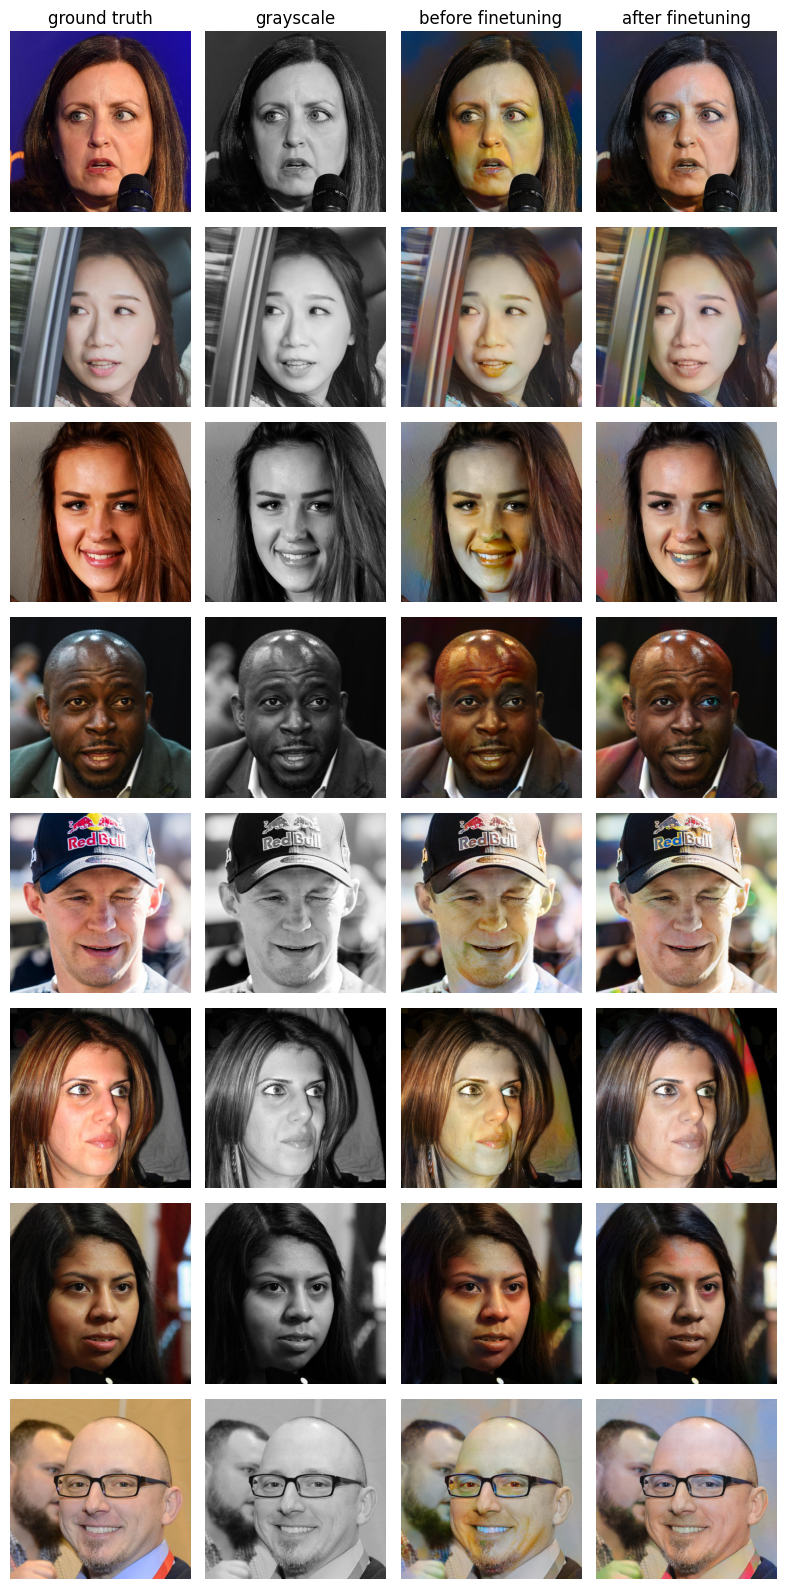

In [6]:
visualize(model1,model2, val_path="data/faces_val", num_images= 8, seed = 33)

# Evaluation

In [8]:
avg_deltaE(model1, "data/faces_val", model_type="GAN", seed = 13, size = 50)

  0%|          | 0/50 [00:00<?, ?it/s]

100%|██████████| 50/50 [01:52<00:00,  2.26s/it]


11.223632033161056

In [8]:
avg_deltaE(model2, "data/faces_val", model_type="GAN", seed = 13, size = 50)

100%|██████████| 10/10 [00:19<00:00,  1.95s/it]


8.361004621762401

In [9]:
mean_chroma(model2, "data/faces_val", seed = 13, size = 50)

100%|██████████| 10/10 [00:17<00:00,  1.75s/it]


34.03122406005859

In [ ]:
mse(model1, "data/faces_val", model_type="GAN", seed = 13, size = 50)

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:20<00:00,  2.09s/it]


452.4047543843587

In [11]:
mse(model2, "faces_val", model_type="GAN", seed = 13, size = 50)

100%|██████████| 10/10 [00:18<00:00,  1.81s/it]


452.10172831217443